In [1]:
# 1 Importing 
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
# Reading file 
df=pd.read_csv('-Telco-Customer-Churn.csv')

In [3]:
# 2. Data Inspection : 

In [4]:
# 2.1 First five rows of dataframe 
df.head()
#df.columns

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
#2.2 Information about dataframe 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
#2.3 Total numbers of rows and columns 
df.shape

(7043, 21)

In [7]:
#2.4 Duplicated rows 
df.duplicated().sum()

np.int64(0)

In [8]:
#2.5 Unique values in gender for data standardization
df['gender'].unique()

array(['Female', 'Male'], dtype=object)

In [9]:
#2.6 Null values in dataframe 
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [10]:
#2.7 Checking blank values in Total charges column
(df['TotalCharges'].astype(str).str.strip()=='').sum()

np.int64(11)

In [11]:
#2.8 Checking unique values for all the columns for data standardization

df1=df[['SeniorCitizen','Partner','Dependents','PhoneService','MultipleLines','InternetService','OnlineSecurity',
    'OnlineBackup', 'DeviceProtection', 'TechSupport',  'StreamingTV', 'StreamingMovies', 'Contract', 
    'PaperlessBilling', 'PaymentMethod','Churn']]

for column in df1:
    print(f'{column} : {df[column].unique()}')


SeniorCitizen : [0 1]
Partner : ['Yes' 'No']
Dependents : ['No' 'Yes']
PhoneService : ['No' 'Yes']
MultipleLines : ['No phone service' 'No' 'Yes']
InternetService : ['DSL' 'Fiber optic' 'No']
OnlineSecurity : ['No' 'Yes' 'No internet service']
OnlineBackup : ['Yes' 'No' 'No internet service']
DeviceProtection : ['No' 'Yes' 'No internet service']
TechSupport : ['No' 'Yes' 'No internet service']
StreamingTV : ['No' 'Yes' 'No internet service']
StreamingMovies : ['No' 'Yes' 'No internet service']
Contract : ['Month-to-month' 'One year' 'Two year']
PaperlessBilling : ['Yes' 'No']
PaymentMethod : ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
Churn : ['No' 'Yes']


In [12]:
# 3.Data cleaning 

In [13]:
# 3.1. Filling blank values in Total charges
df['TotalCharges']=np.where(df['tenure']==0,'0',df['TotalCharges'])

In [14]:
# 3.2. Change type : Total Charges - float
df['TotalCharges']=df['TotalCharges'].astype(float)

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [16]:
# 4 Feature Engineering 

In [17]:
# 4.1 Adding Segments according to tenure 
conditions= [(df['tenure']>=0) & (df['tenure']<=18),
             (df['tenure']>18) & (df['tenure']<=36),
             (df['tenure']>36) & (df['tenure']<=54),
             (df['tenure']>54) & (df['tenure']<=72),
             (df['tenure']>72)]

choice=['0-18','19-36','37-54','55-72','73 and more']

df['Tenure_Range']=np.select(conditions, choice, default='unknown')
             

In [18]:
df[['tenure','Tenure_Range']].head()

,tenure,Tenure_Range
0,1,0-18
1,34,19-36
2,2,0-18
3,45,37-54
4,2,0-18


In [19]:
#4.2 Counting Total services a customer use 
def count_services(row):
    total = 0
    if row['PhoneService'] == 'Yes':
        total += 1
    if row['MultipleLines'] == 'Yes':
        total += 1
    if row['InternetService'] != 'No':
        total += 1
    for col in ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                'TechSupport', 'StreamingTV', 'StreamingMovies']:
        if row[col] == 'Yes':
            total += 1
    return total

df['TotalServices'] = df.apply(count_services, axis=1)
             


In [20]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Tenure_Range,TotalServices
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0-18,2
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.50,No,19-36,4
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0-18,4
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,37-54,4
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0-18,2


In [21]:
# 5. Churn Analysis

In [22]:
# 5.1 Total Customers 

customer=df['customerID'].nunique()
print("Total Customers : ",customer)

Total Customers :  7043


In [23]:
#5.2 Churned Customers

churned_customer=(df['Churn']=='Yes').sum()
print('Total Churned Customers : ',churned_customer)

Total Churned Customers :  1869


In [24]:
# 5.3 Churn Rate 

churn=(df['Churn']=='Yes').mean()*100
print("The Churn Rate is : ",round(churn,2),"%")

The Churn Rate is :  26.54 %


In [25]:
# 5.4 Retention Rate

Retention=(df['Churn']=='No').mean()*100
print("The Retention Rate is : ",round(Retention,2),"%")

The Retention Rate is :  73.46 %


In [26]:
# 5.5 Monthly Revenue loss 

loss=np.where(df['Churn']=='Yes',df['MonthlyCharges'],0).sum()
print('Monthly Revenue loss : ',round(loss,2))

Monthly Revenue loss :  139130.85


In [27]:
# 5.6 Average tenure by churned customers

avg_tenure=df.loc[df['Churn']=='Yes' , 'tenure'].mean()
print('The Average Tenure : ',round(avg_tenure,2))

The Average Tenure :  17.98


In [28]:
#5.7 Average service used by churned customers

service=df.loc[df['Churn']=='Yes' , 'TotalServices'].mean()
print('Average Service per Churned Customers : ',round(service,0))

Average Service per Churned Customers :  4.0


In [29]:
#5.8 Average revenue per user monthly 

arup_monthly=df['MonthlyCharges'].mean()
print('The Average revenue per user monthly : ',round(arup_monthly,2))

The Average revenue per user monthly :  64.76


In [30]:
#5.9 Churn by Contract Type 

churn_by_contract_type=(df['Churn']=='Yes').groupby(df['Contract']).mean().mul(100).round(2).reset_index(name='churn_by_contract_type')
churn_by_contract_type 

,Contract,churn_by_contract_type
0,Month-to-month,42.71
1,One year,11.27
2,Two year,2.83


In [31]:
#5.10 Churn by tenure Range

churn_by_Tenure_Range=(df['Churn']=='Yes').groupby(df['Tenure_Range']).mean().mul(100).round(2).reset_index(name='churn_by_Tenure_Range')
churn_by_Tenure_Range

,Tenure_Range,churn_by_Tenure_Range
0,0-18,44.40
1,19-36,22.71
2,37-54,18.02
3,55-72,7.97


In [32]:
#5.11 Churn by senior citizens

senior_citizens=(df['Churn']=='Yes').groupby(df['SeniorCitizen']).mean().mul(100).round(2).reset_index()
senior_citizens

,SeniorCitizen,Churn
0,0,23.61
1,1,41.68


In [33]:
#5.12 Churn by Internet service

internet=(df['Churn']=='Yes').groupby(df['InternetService']).sum()
print(internet)

InternetService
DSL             459
Fiber optic    1297
No              113
Name: Churn, dtype: int64


In [34]:
#5.13 Churn by Partner status

service=(df['Churn']=='Yes').groupby(df['Partner']).mean().mul(100).round(2).reset_index()
service

,Partner,Churn
0,No,32.96
1,Yes,19.66


In [35]:
import warnings
warnings.filterwarnings('ignore')


In [36]:
#5.14 Churned customers by gender and senior citizen

churn_by_senior=df[df['Churn']=='Yes'].pivot_table(index=['SeniorCitizen','gender'],aggfunc={'Churn':'count'})
churn_by_senior

Churn
SeniorCitizen gender       
0             Female    699
              Male      694
1             Female    240
              Male      236

In [37]:
# 5.15 Correlation between churn and total services

df_corr=df[['Churn','TotalServices']]
df_corr['Churn']=np.where(df_corr['Churn']=='Yes',1,0)
correlation=df_corr['Churn'].corr(df_corr['TotalServices'])
print('The correlation between Churn and Total Service is : ',round(correlation,2))

The correlation between Churn and Total Service is :  -0.02


In [38]:
# 5.16 Distribution of senior citizen 

senior_citizen=df.loc[df['Churn']=='Yes' , 'SeniorCitizen'].mean()*100
print('Percentage of senior customer in churned customers :',round(senior_citizen,2),'%')

Percentage of senior customer in churned customers : 25.47 %


In [39]:
#6 Data Visualization

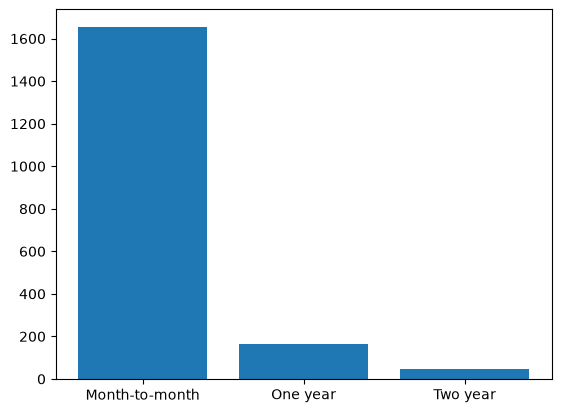

In [40]:
#6.1 Churn rate by contract type 
abc=df[df['Churn']=='Yes'].pivot_table(index=['Contract'],aggfunc={'Churn':'count'})

plt.bar(abc.index,abc['Churn'])
plt.show()

In [41]:
#6.2 Correlation
df_visuals=df[['SeniorCitizen','Partner','Dependents','Tenure_Range','TotalServices','Churn']]
order={'Partner':['No','Yes'],'Dependents':['No','Yes'],'Churn':['No','Yes'],'Tenure_Range':['0-18','19-36','37-54','55-72']}
for col,ordd in order.items():
    df_visuals[col] = pd.Categorical(df_visuals[col].astype('category'),categories=ordd,ordered=True).codes
df_visuals  

,SeniorCitizen,Partner,Dependents,Tenure_Range,TotalServices,Churn
0,0,1,0,0,2,0
1,0,0,0,1,4,0
2,0,0,0,0,4,1
3,0,0,0,2,4,0
4,0,0,0,0,2,1
...,...,...,...,...,...,...
7038,0,1,1,1,8,0
7039,0,1,1,3,7,0
7040,0,1,1,0,2,0
7041,1,1,0,0,3,1


<Axes: >

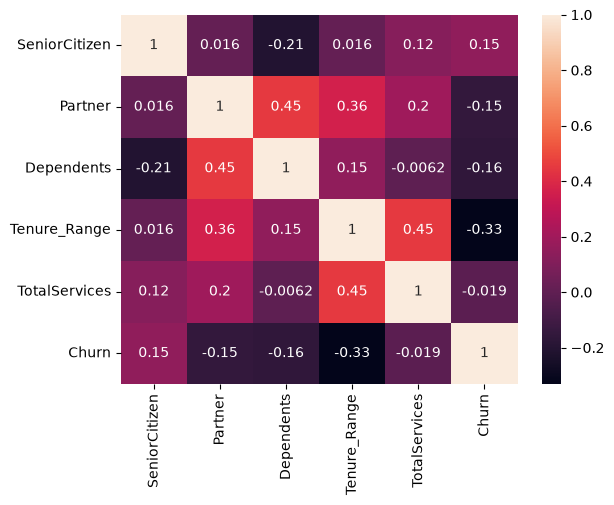

In [42]:
sns.heatmap(df_visuals.corr(), annot=True)